# Week 3 - Noise filtering
Necessary imports

In [1]:
from __future__ import annotations
import cv2
import matplotlib.pyplot as plt
import pickle
from dataclasses import dataclass
from pathlib import Path
import random
import math

import numpy as np
from scipy.ndimage import gaussian_filter1d, binary_fill_holes, gaussian_filter1d

In [2]:
def find_project_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "data").is_dir() and (directory / "src").is_dir():
            return directory
    raise FileNotFoundError("Could not find the project root")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"

## 0. Image and ground truth loading
Code snippet from week1 code so it stays with a persistent method

In [3]:
@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    # Sorting is essential: submission row i must correspond to query image i.
    paths = tuple(sorted(directory.glob("*.jpg")))
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


In [8]:
train_dataset = load_image_dataset(f"{DATA_DIR}/qsd1_w3")
non_augmented_data = load_image_dataset(f"{DATA_DIR}/qsd1_w3/non_augmented")
ground_truth = load_ground_truth(f"{DATA_DIR}/qsd1_w3/gt_corresps.pkl")

## Noise observation and analysis
Analyzing the type of noise that is present in the images will help us find the correct filters to reduce it successfully.
To do so we must observe the images and find which noise patterns emerge when plotted.

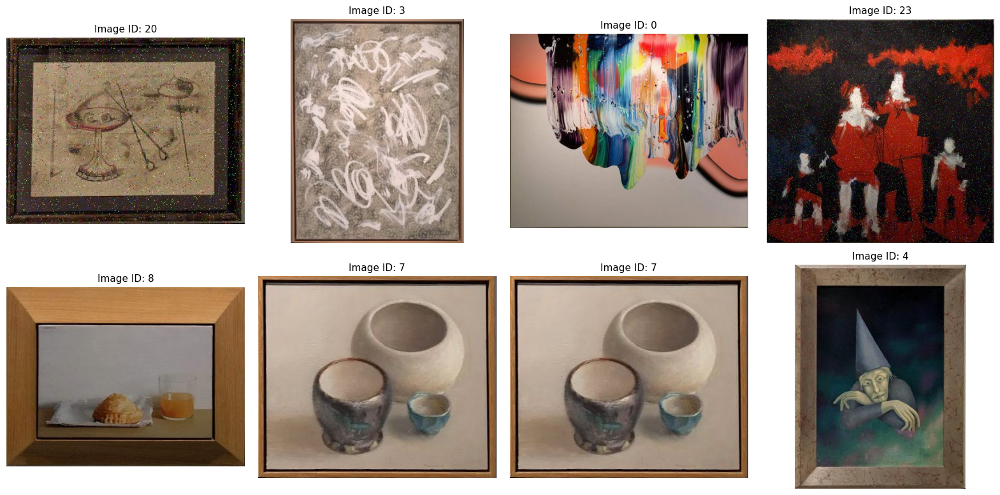

In [9]:
random.seed(42)
n_images = 8

n_cols = 4 
n_rows = math.ceil(n_images / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(n_cols * 4, n_rows * 4)
)

# Make axes iterable even if there's only one row or column
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(n_images):
    random_index = random.randint(0, len(train_dataset.paths) - 1)
    image_path = train_dataset.paths[random_index]
    image_id_value = train_dataset.ids[random_index]

    # Load image and convert BGR to RGB
    image = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(image_rgb)
    axes[i].set_title(f"Image ID: {image_id_value}", fontsize=11)
    axes[i].axis("off")

# Hide unused grid cells
for j in range(n_images, len(axes)):
    axes[j].axis("off")

plt.tight_layout(pad=1.5)
plt.show()


In this sample we can see that image 20 has a considerable ammount of noise present on it, to further analyse which type of noise it is we can plot the original vs noisy image and it's difference.

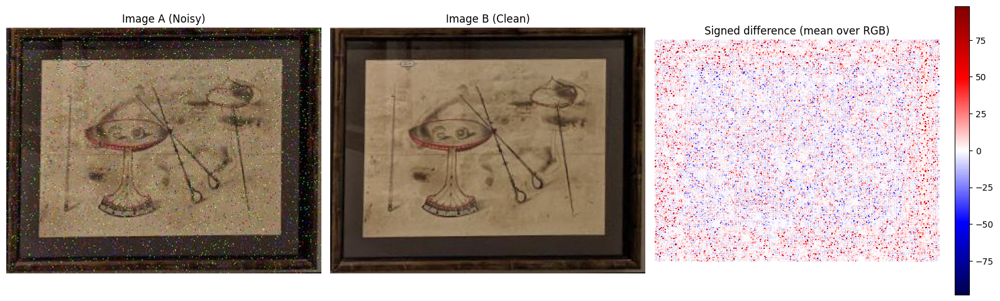

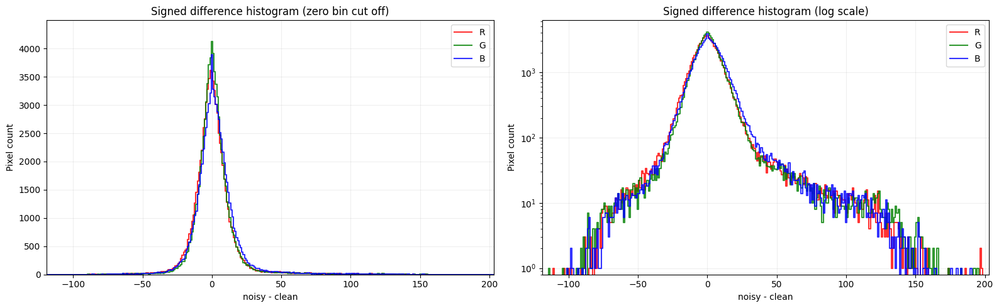

In [10]:
def compute_histograms_and_difference(a, b, plot=False):
    """
    Display noisy image, clean image, their signed difference,
    and the per-channel histograms of the difference.

    Returns
    -------
    image_a, image_b, difference (signed, noisy - clean), difference_histogram
    """

    def load_rgb(path):
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f"Could not load image: {path}")
        return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image_a = load_rgb(a)
    image_b = load_rgb(b)

    if image_a.shape != image_b.shape:
        raise ValueError(
            f"Image dimensions differ: {image_a.shape} vs {image_b.shape}"
        )

    # Signed difference (int16 avoids uint8 wraparound)
    difference = image_a.astype(np.int16) - image_b.astype(np.int16)

    # One integer bin per possible difference value: -255 ... 255
    bin_edges = np.arange(-255.5, 256.5, 1.0)
    values = np.arange(-255, 256)

    difference_histogram = np.concatenate([
        np.histogram(difference[:, :, c].ravel(), bins=bin_edges)[0]
        for c in range(3)
    ])

    if plot:
        n = len(values)
        hists = [difference_histogram[c * n:(c + 1) * n] for c in range(3)]
        colors = ["red", "green", "blue"]
        names = ["R", "G", "B"]

        # ---------- Images ----------
        lim = max(np.percentile(np.abs(difference), 99.5), 1)

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))
        axes[0].imshow(image_a)
        axes[0].set_title("Image A (Noisy)")
        axes[1].imshow(image_b)
        axes[1].set_title("Image B (Clean)")
        im = axes[2].imshow(difference.mean(axis=2), cmap="seismic",
                            vmin=-lim, vmax=lim)
        axes[2].set_title("Signed difference (mean over RGB)")
        plt.colorbar(im, ax=axes[2], fraction=0.046)
        for ax in axes:
            ax.axis("off")
        plt.tight_layout()
        plt.show()

        # ---------- Histograms ----------
        # Zoom the x-axis onto where the data actually lives
        nonzero = np.where(sum(hists) > 0)[0]
        x_min = max(values[nonzero.min()] - 5, -255)
        x_max = min(values[nonzero.max()] + 5, 255)

        fig, axes = plt.subplots(1, 2, figsize=(16, 5))

        for h, col, name in zip(hists, colors, names):
            axes[0].step(values, h, where="mid", color=col, alpha=0.8, label=name)
            axes[1].step(values, h, where="mid", color=col, alpha=0.8, label=name)

        # Left: linear scale, with the zero bin cut off so the rest is visible
        peak_wo_zero = max(np.delete(h, 255).max() for h in hists)
        axes[0].set_ylim(0, peak_wo_zero * 1.15)
        axes[0].set_title("Signed difference histogram (zero bin cut off)")

        # Right: log scale, shows the tails
        axes[1].set_yscale("log")
        axes[1].set_ylim(bottom=0.8)
        axes[1].set_title("Signed difference histogram (log scale)")

        for ax in axes:
            ax.set_xlim(x_min, x_max)
            ax.set_xlabel("noisy - clean")
            ax.set_ylabel("Pixel count")
            ax.grid(alpha=0.2)
            ax.legend()

        plt.tight_layout()
        plt.show()

    return image_a, image_b, difference, difference_histogram



noisy_image = train_dataset.paths[20]
clean_image = non_augmented_data.paths[20]
# Example
image_a, image_b, difference, difference_histogram = (
    compute_histograms_and_difference(noisy_image, clean_image, plot=True)
)

With this distribution of the noise we can distinguish a form that starts with a gaussian-like shape but turns greater on the wings of it. This heavily leads us to thinking that this could be some kind of gaussian noise or even a type of impulse/salt-pepper noise, as we can see that the gaussian presents a small deviation $\sigma$ on the non logarithmic representation of the data, for this cases the most common implementations are the median and average filters, which we will apply and compare the results.

## Filter comparison

In [11]:
filtered_image_median = cv2.medianBlur(image_a, 3)

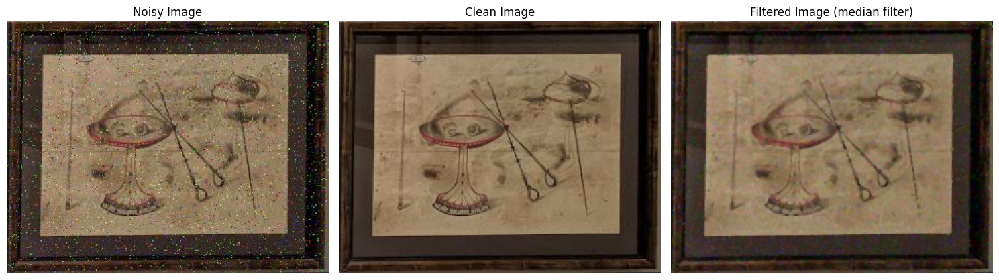

In [12]:
# compare the original noisy image, the clean image, and the filtered image
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image_a)
plt.title("Noisy Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(image_b)
plt.title("Clean Image")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(filtered_image_median)
plt.title("Filtered Image (median filter)")
plt.axis("off")
plt.tight_layout()
plt.show()


## Filter performance analysis

In [13]:
filters = {
    "Median Filter": lambda img: cv2.medianBlur(img, 3),
    "Gaussian Filter": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "Mean Filter": lambda img: cv2.blur(img, (3, 3)),
    "Bilateral Filter": lambda img: cv2.bilateralFilter(img, 9, 75, 75),
    "Non local Means Filter": lambda img: cv2.fastNlMeansDenoisingColored(img, None, 10, 10, 7, 21),}



## Filter evaluation against the non-augmented dataset
Each noisy image is filtered and compared with the clean image having the same numeric ID. The plots show the mean and standard deviation across the dataset.

In [14]:
from skimage.metrics import structural_similarity

def read_rgb(path: Path) -> np.ndarray:
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def evaluate_filters(
    noisy_dataset: ImageDataset,
    clean_dataset: ImageDataset,
    filter_functions: dict[str, callable],
) -> dict[str, dict[str, np.ndarray | float]]:
    """Compute per-image MSE and SSIM for every filter."""
    clean_by_id = dict(zip(clean_dataset.ids.tolist(), clean_dataset.paths))
    missing_ids = sorted(set(noisy_dataset.ids.tolist()) - set(clean_by_id))
    if missing_ids:
        raise ValueError(f"No clean counterpart for image IDs: {missing_ids}")

    metrics = {}
    for filter_name, filter_function in filter_functions.items():
        mse_values = []
        ssim_values = []
        for noisy_path, image_id_value in zip(noisy_dataset.paths, noisy_dataset.ids):
            noisy = read_rgb(noisy_path)
            clean = read_rgb(clean_by_id[int(image_id_value)])
            if noisy.shape != clean.shape:
                raise ValueError(
                    f"Image shape mismatch for ID {image_id_value}: "
                    f"{noisy.shape} vs {clean.shape}"
                )

            filtered = filter_function(noisy)
            mse_values.append(np.mean((filtered.astype(np.float32) - clean) ** 2))
            ssim_values.append(
                structural_similarity(clean, filtered, channel_axis=2, data_range=255)
            )

        metrics[filter_name] = {
            "mse": np.asarray(mse_values),
            "ssim": np.asarray(ssim_values),
        }
    return metrics


filter_metrics = evaluate_filters(train_dataset, non_augmented_data, filters)

summary = []
for filter_name, values in filter_metrics.items():
    summary.append({
        "Filter": filter_name,
        "MSE mean": values["mse"].mean(),
        "MSE std": values["mse"].std(),
        "SSIM mean": values["ssim"].mean(),
        "SSIM std": values["ssim"].std(),
    })

import pandas as pd
summary_df = pd.DataFrame(summary).set_index("Filter")
display(summary_df.round(4))

,MSE mean,MSE std,SSIM mean,SSIM std
Filter,,,,
Median Filter,71.870102,116.600800,0.9005,0.0860
Gaussian Filter,77.183998,109.972900,0.8929,0.1065
Mean Filter,99.123001,125.905800,0.8737,0.1007
Bilateral Filter,84.435204,108.995499,0.8312,0.1178
Non local Means Filter,94.221397,123.580498,0.8281,0.1190


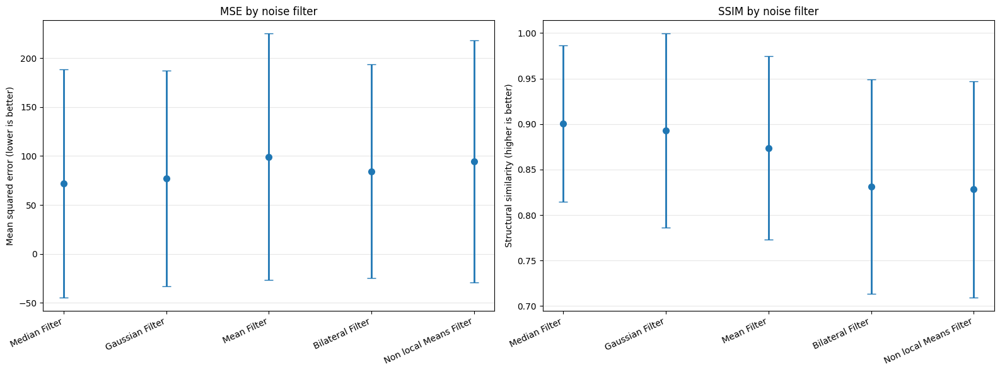

In [15]:
filter_names = list(filter_metrics)
x = np.arange(len(filter_names))
means = {metric: [filter_metrics[name][metric].mean() for name in filter_names]
         for metric in ("mse", "ssim")}
stds = {metric: [filter_metrics[name][metric].std() for name in filter_names]
        for metric in ("mse", "ssim")}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for axis, metric, title, ylabel in zip(
    axes,
    ("mse", "ssim"),
    ("MSE by noise filter", "SSIM by noise filter"),
    ("Mean squared error (lower is better)", "Structural similarity (higher is better)"),
):
    axis.errorbar(
        x, means[metric], yerr=stds[metric], fmt="o", capsize=5,
        linewidth=2, markersize=7,
    )
    axis.set_xticks(x, filter_names, rotation=25, ha="right")
    axis.set_title(title)
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

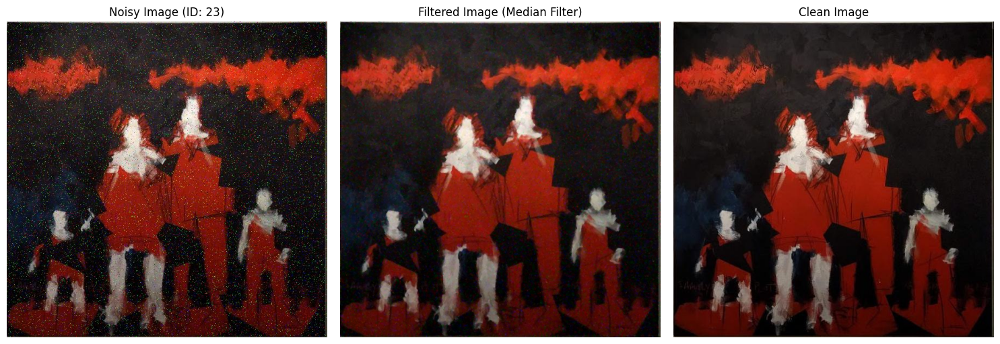

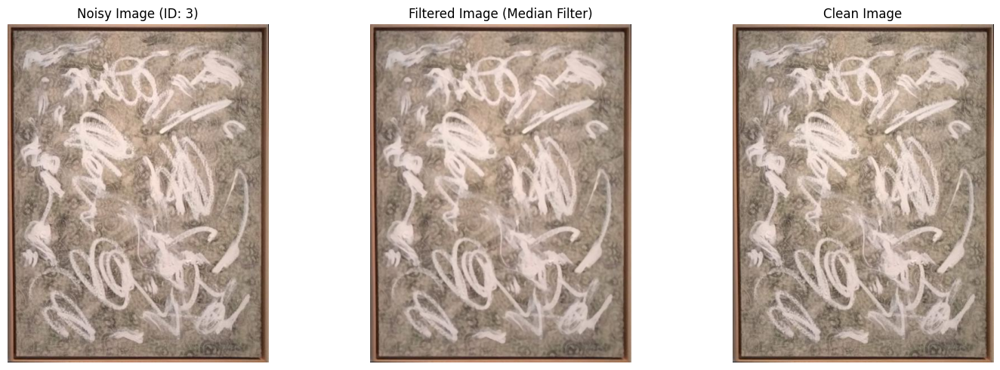

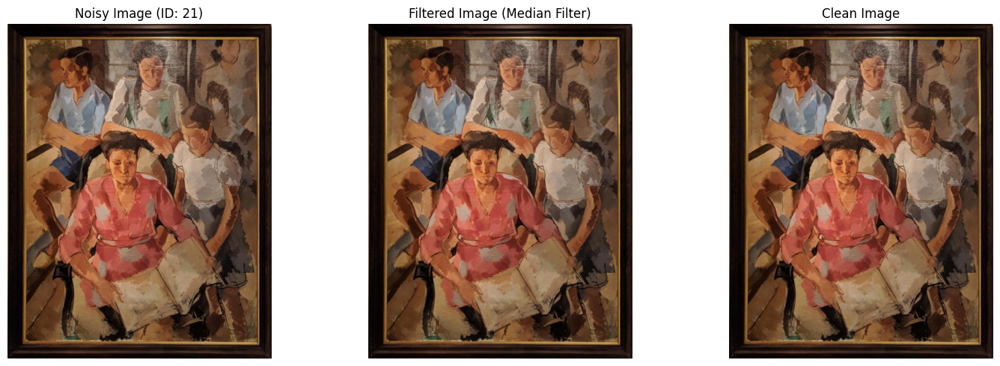

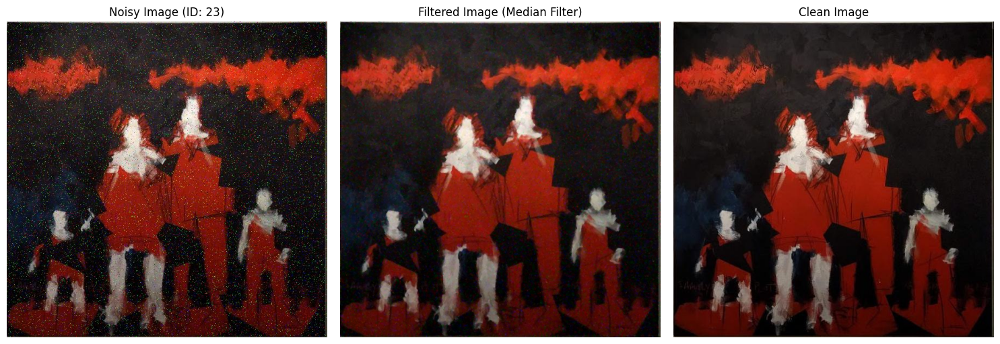

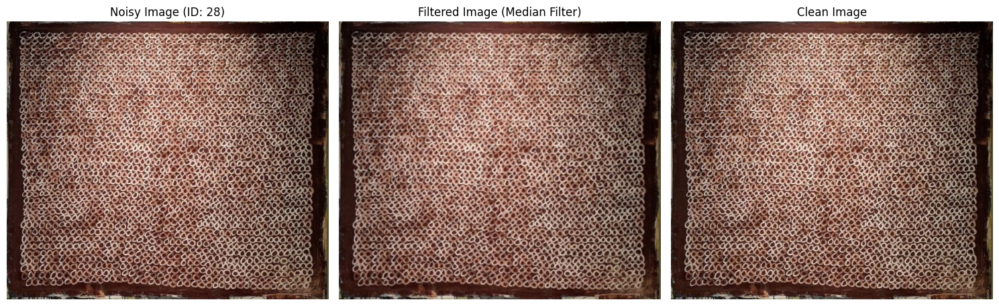

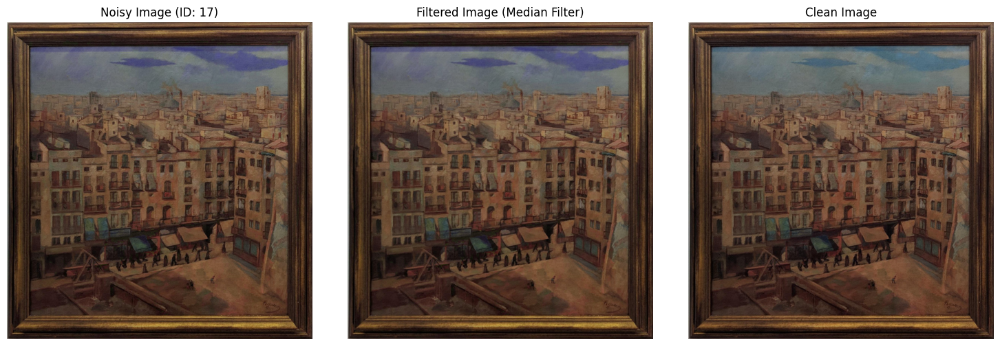

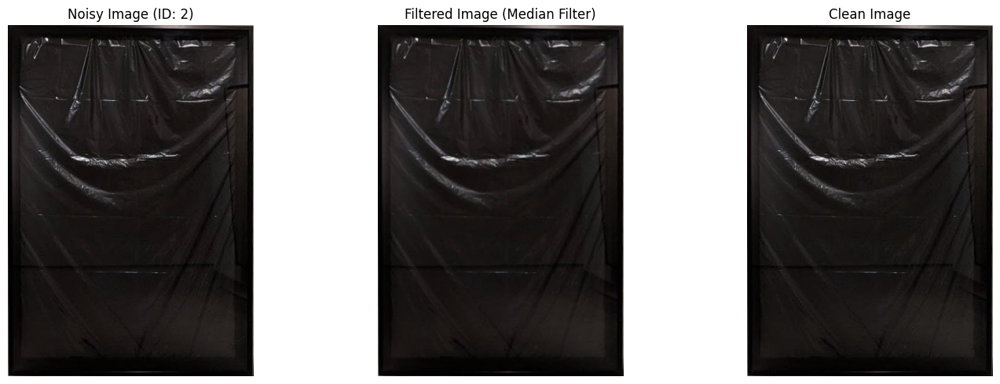

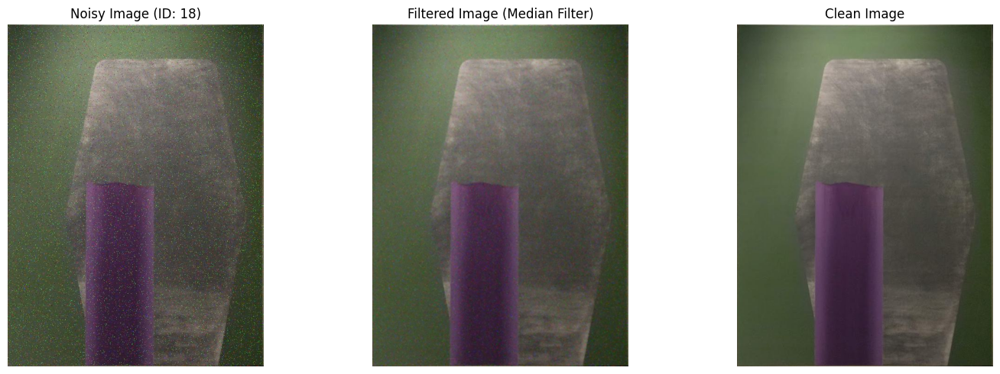

In [16]:
# Display the original noisy image, the filtered image, and the clean image for comparison for a random sample of images
n_images = 8

for i in range(n_images):
    random_index = random.randint(0, len(train_dataset.paths) - 1)
    image_path = train_dataset.paths[random_index]
    image_id_value = train_dataset.ids[random_index]

    # Load images
    noisy_image = read_rgb(image_path)
    clean_image = read_rgb(non_augmented_data.paths[random_index])
    filtered_image = cv2.medianBlur(noisy_image, 3)

    # Display images
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(noisy_image)
    plt.title(f"Noisy Image (ID: {image_id_value})")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(filtered_image)
    plt.title("Filtered Image (Median Filter)")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(clean_image)
    plt.title("Clean Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

## Task 2 - Texture descriptors (QSD1-W3)

We implement two texture descriptors, **LBP** and **DCT**, and evaluate retrieval on QSD1-W3 using **only texture** (grayscale, no colour). Both are computed per block and concatenated, as in the colour block histograms. The queries are filtered with the median filter from Task 1 before computing the descriptors, because some of them are noisy.

In [17]:
db_dataset = load_image_dataset(f"{DATA_DIR}/BBDD")
query_dataset = train_dataset            # QSD1-W3: the noisy / colour-changed queries
read = lambda p: cv2.imread(p.as_posix())
db_imgs = [read(p) for p in db_dataset.paths]
q_imgs  = [read(p) for p in query_dataset.paths]
db_ids = db_dataset.ids
print(len(db_imgs), len(q_imgs), len(ground_truth))     # expect 287 30 30

287 30 30


In [47]:
def to_gray(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

def preprocess(img_bgr, denoise=True):
    return cv2.medianBlur(img_bgr, 3) if denoise else img_bgr

def hellinger(q, D):
    return np.sqrt(((np.sqrt(q) - np.sqrt(D)) ** 2).sum(axis=1))
def chi2(q, D, eps=1e-10):
    return 0.5 * (((q - D) ** 2) / (q + D + eps)).sum(axis=1)
def l1(q, D):
    return np.abs(q - D).sum(axis=1)
def l2(q, D):
    return np.sqrt(((q - D) ** 2).sum(axis=1))
def cosine(q, D):
    qn = q / (np.linalg.norm(q) + 1e-12)
    Dn = D / (np.linalg.norm(D, axis=1, keepdims=True) + 1e-12)
    return 1 - Dn @ qn

def map_at_k(results, gt, k):
    aps = []
    for res, rel in zip(results, gt):
        ap, hits = 0.0, 0
        for r, img_id in enumerate(res[:k], start=1):
            if img_id in rel:
                hits += 1
                ap += hits / r
        aps.append(ap / min(len(rel), k))
    return float(np.mean(aps))

def evaluate(desc_fn, distances, db_imgs, q_imgs, db_ids, gt,
             denoise_queries=True, denoise_db=False, size=None):
    """Descriptors -> distances -> mAP@1 / mAP@5.
    denoise_queries / denoise_db: apply the median filter to queries / database images.
    size: if given, resize every image to size x size before the descriptor."""
    def prep(im, denoise):
        im = preprocess(im, denoise)
        return cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA) if size else im
    D = np.array([desc_fn(to_gray(prep(im, denoise_db))) for im in db_imgs])
    Q = np.array([desc_fn(to_gray(prep(im, denoise_queries))) for im in q_imgs])
    out = {}
    for name, dist in distances.items():
        res = [[int(db_ids[i]) for i in np.argsort(dist(q, D), kind="stable")[:10]] for q in Q]
        out[name] = (map_at_k(res, gt, 1), map_at_k(res, gt, 5), res)
    return out

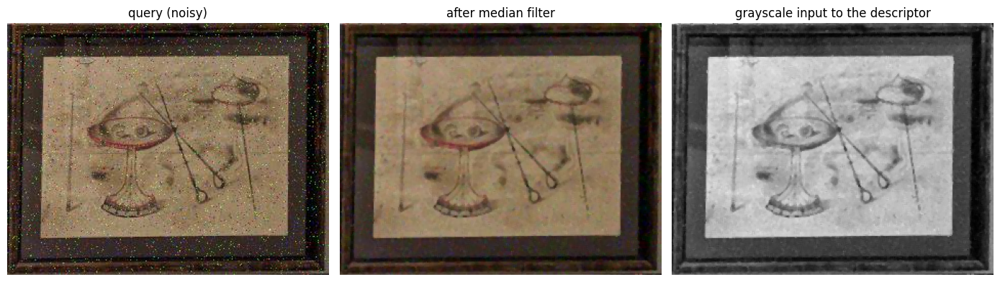

In [19]:
i = 20                                    # the noisy example you analysed in Task 1
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(cv2.cvtColor(q_imgs[i], cv2.COLOR_BGR2RGB)); ax[0].set_title("query (noisy)")
ax[1].imshow(cv2.cvtColor(preprocess(q_imgs[i]), cv2.COLOR_BGR2RGB)); ax[1].set_title("after median filter")
ax[2].imshow(to_gray(preprocess(q_imgs[i])), cmap="gray"); ax[2].set_title("grayscale input to the descriptor")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### DCT descriptor
Each block is resized to a fixed size (16×16), transformed with the 2D DCT (`cv2.dct`) and read in zig-zag order, from low to high frequency. We keep the first N coefficients, skipping the first one (DC), which is the mean brightness and not texture. The coefficients of all blocks are concatenated and the vector is L2-normalised.

In [20]:
def zigzag_indices(n):
    idx = [(i, j) for i in range(n) for j in range(n)]
    return sorted(idx, key=lambda p: (p[0] + p[1], p[1] if (p[0] + p[1]) % 2 == 0 else p[0]))

_ZZ = {}
def dct_descriptor(gray, grid=8, block_size=16, n_coefs=10, skip_dc=True):
    if block_size not in _ZZ:
        _ZZ[block_size] = zigzag_indices(block_size)
    start = 1 if skip_dc else 0
    zz = _ZZ[block_size][start:start + n_coefs]
    h, w = gray.shape
    ys = np.linspace(0, h, grid + 1, dtype=int); xs = np.linspace(0, w, grid + 1, dtype=int)
    feats = []
    for i in range(grid):
        for j in range(grid):
            blk = gray[ys[i]:ys[i+1], xs[j]:xs[j+1]]
            blk = cv2.resize(blk, (block_size, block_size), interpolation=cv2.INTER_AREA).astype(np.float32)
            c = cv2.dct(blk)
            feats.append([c[a, b] for a, b in zz])
    v = np.asarray(feats, np.float32).ravel()
    return v / (np.linalg.norm(v) + 1e-12)

print(dct_descriptor(to_gray(db_imgs[0])).shape)      # 8x8 blocks x 10 coefficients = (640,)

(640,)


In [21]:
dists_vec = {"l2": l2, "l1": l1, "cosine": cosine}
dct_rows = []
for grid in (4, 8, 12):
    for n_coefs in (5, 10, 20):
        out = evaluate(lambda g: dct_descriptor(g, grid, 16, n_coefs), dists_vec, db_imgs, q_imgs, db_ids, ground_truth)
        for dname, (m1, m5, _) in out.items():
            dct_rows.append((grid, n_coefs, dname, m1, m5))
            print(f"grid {grid:>2}  coefs {n_coefs:>2}  {dname:<7} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

/var/folders/pp/34643w6n4cxb13gv856w0dw40000gn/T/ipykernel_11268/4180116699.py:18: RuntimeWarning: divide by zero encountered in matmul
  return 1 - Dn @ qn
/var/folders/pp/34643w6n4cxb13gv856w0dw40000gn/T/ipykernel_11268/4180116699.py:18: RuntimeWarning: overflow encountered in matmul
  return 1 - Dn @ qn
/var/folders/pp/34643w6n4cxb13gv856w0dw40000gn/T/ipykernel_11268/4180116699.py:18: RuntimeWarning: invalid value encountered in matmul
  return 1 - Dn @ qn


grid  4  coefs  5  l2      mAP@1 0.933  mAP@5 0.933
grid  4  coefs  5  l1      mAP@1 0.933  mAP@5 0.944
grid  4  coefs  5  cosine  mAP@1 0.933  mAP@5 0.933
grid  4  coefs 10  l2      mAP@1 0.933  mAP@5 0.951
grid  4  coefs 10  l1      mAP@1 0.967  mAP@5 0.983
grid  4  coefs 10  cosine  mAP@1 0.933  mAP@5 0.951
grid  4  coefs 20  l2      mAP@1 0.967  mAP@5 0.975
grid  4  coefs 20  l1      mAP@1 1.000  mAP@5 1.000
grid  4  coefs 20  cosine  mAP@1 0.967  mAP@5 0.975
grid  8  coefs  5  l2      mAP@1 0.967  mAP@5 0.967
grid  8  coefs  5  l1      mAP@1 1.000  mAP@5 1.000
grid  8  coefs  5  cosine  mAP@1 0.967  mAP@5 0.967
grid  8  coefs 10  l2      mAP@1 0.933  mAP@5 0.967
grid  8  coefs 10  l1      mAP@1 0.967  mAP@5 0.983
grid  8  coefs 10  cosine  mAP@1 0.967  mAP@5 0.983
grid  8  coefs 20  l2      mAP@1 0.933  mAP@5 0.961
grid  8  coefs 20  l1      mAP@1 0.967  mAP@5 0.983
grid  8  coefs 20  cosine  mAP@1 0.933  mAP@5 0.967
grid 12  coefs  5  l2      mAP@1 0.967  mAP@5 0.983
grid 12  coe

In [22]:
dct_fn = lambda g: dct_descriptor(g, 8, 16, 10)
for den in (False, True):
    out = evaluate(dct_fn, {"l2": l2, "l1": l1}, db_imgs, q_imgs, db_ids, ground_truth, denoise_queries=den)
    for dname, (m1, m5, _) in out.items():
        print(f"median filter {den!s:<5}  {dname:<3}  mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

median filter False  l2   mAP@1 0.933  mAP@5 0.967
median filter False  l1   mAP@1 0.967  mAP@5 0.983
median filter True   l2   mAP@1 0.933  mAP@5 0.967
median filter True   l1   mAP@1 0.967  mAP@5 0.983


In [23]:
g_noisy = to_gray(q_imgs[20])
g_filt  = to_gray(preprocess(q_imgs[20]))
print(np.linalg.norm(dct_fn(g_noisy) - dct_fn(g_filt)))

0.067017056


### LBP (Local Binary Pattern)
For every pixel we compare it with its 8 neighbours: each neighbour that is greater than or equal to the centre gives a 1, otherwise a 0. The 8 bits form a number from 0 to 255 (the pixel's local pattern). We use scikit-image's `local_binary_pattern` to get the codes, split the image into N×N blocks, take the normalised histogram of the 256 codes in each block, and concatenate them. The multiscale version uses several neighbourhoods (P points at radius R) with the uniform-pattern histogram (P+2 bins).

In [37]:
from skimage.feature import local_binary_pattern

def block_hist(code_img, grid, n_bins):
    h, w = code_img.shape
    ys = np.linspace(0, h, grid + 1, dtype=int); xs = np.linspace(0, w, grid + 1, dtype=int)
    out = []
    for i in range(grid):
        for j in range(grid):
            blk = code_img[ys[i]:ys[i+1], xs[j]:xs[j+1]]
            hist = np.bincount(blk.ravel(), minlength=n_bins).astype(np.float32)
            out.append(hist / max(hist.sum(), 1e-12))
    return np.concatenate(out) / grid**2

def lbp_descriptor(gray, grid=4, scales=((8, 1.0),), uniform=False):
    parts = []
    for P, R in scales:
        method = "default" if ((P, R) == (8, 1.0) and not uniform) else "uniform"
        codes = local_binary_pattern(gray, P, R, method=method).astype(np.int32)
        n_bins = 256 if method == "default" else P + 2
        parts.append(block_hist(codes, grid, n_bins))
    d = np.concatenate(parts)
    return d / d.sum()

print(lbp_descriptor(to_gray(db_imgs[0]), grid=4).shape)      # 4x4 blocks x 256 bins = (4096,)

(4096,)


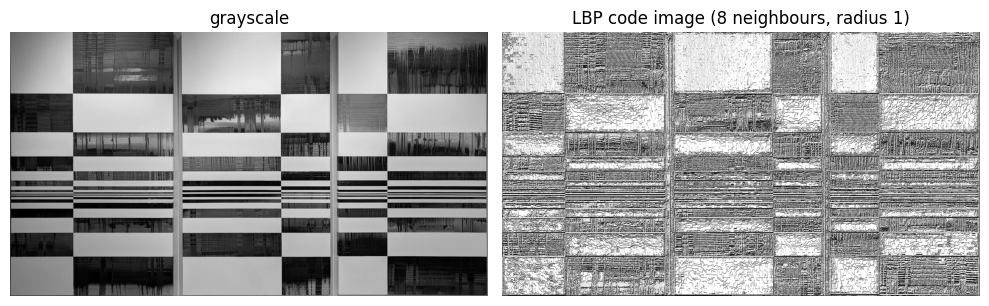

In [25]:
g = to_gray(db_imgs[0])
codes = local_binary_pattern(g, 8, 1.0, method="default")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(g, cmap="gray"); ax[0].set_title("grayscale")
ax[1].imshow(codes, cmap="gray"); ax[1].set_title("LBP code image (8 neighbours, radius 1)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

#### First attempt: same pipeline as DCT
We first evaluate LBP exactly as DCT: queries filtered with the median filter, database images untouched, original image size.

In [31]:
dists_hist = {"hellinger": hellinger, "chi2": chi2, "l1": l1}
lbp_rows = []
for grid in (1, 2, 4, 8):
    out = evaluate(lambda g: lbp_descriptor(g, grid), dists_hist, db_imgs, q_imgs, db_ids, ground_truth)
    for dname, (m1, m5, _) in out.items():
        lbp_rows.append((f"8,1 grid {grid}", dname, m1, m5))
        print(f"LBP 8,1     grid {grid}  {dname:<10} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

multi = ((8, 1.0), (12, 2.5), (16, 4.0))
for grid in (2, 4):
    out = evaluate(lambda g: lbp_descriptor(g, grid, multi), dists_hist, db_imgs, q_imgs, db_ids, ground_truth)
    for dname, (m1, m5, _) in out.items():
        lbp_rows.append((f"multiscale grid {grid}", dname, m1, m5))
        print(f"LBP multi   grid {grid}  {dname:<10} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

LBP 8,1     grid 1  hellinger  mAP@1 0.000  mAP@5 0.000
LBP 8,1     grid 1  chi2       mAP@1 0.000  mAP@5 0.000
LBP 8,1     grid 1  l1         mAP@1 0.000  mAP@5 0.000
LBP 8,1     grid 2  hellinger  mAP@1 0.000  mAP@5 0.018
LBP 8,1     grid 2  chi2       mAP@1 0.000  mAP@5 0.019
LBP 8,1     grid 2  l1         mAP@1 0.033  mAP@5 0.047
LBP 8,1     grid 4  hellinger  mAP@1 0.100  mAP@5 0.125
LBP 8,1     grid 4  chi2       mAP@1 0.100  mAP@5 0.128
LBP 8,1     grid 4  l1         mAP@1 0.133  mAP@5 0.142
LBP 8,1     grid 8  hellinger  mAP@1 0.167  mAP@5 0.189
LBP 8,1     grid 8  chi2       mAP@1 0.200  mAP@5 0.218
LBP 8,1     grid 8  l1         mAP@1 0.200  mAP@5 0.230
LBP multi   grid 2  hellinger  mAP@1 0.000  mAP@5 0.000
LBP multi   grid 2  chi2       mAP@1 0.000  mAP@5 0.000
LBP multi   grid 2  l1         mAP@1 0.000  mAP@5 0.000
LBP multi   grid 4  hellinger  mAP@1 0.000  mAP@5 0.047
LBP multi   grid 4  chi2       mAP@1 0.000  mAP@5 0.054
LBP multi   grid 4  l1         mAP@1 0.000  mAP@

**Result of the first attempt: very poor.** With the 8-neighbour LBP, mAP@1 was between 0.000 and 0.200 (a global histogram gave 0.000, which is chance level among 287 paintings), and the multiscale version was even worse (0.000 mAP@1). The same pipeline gave 0.97 with DCT, so we looked for the cause. LBP compares each pixel with its neighbours, so it describes the finest grain of the photo. A possible reason is that the queries (filtered, with different sizes) and the database images (unfiltered) do not have the same fine texture, so their LBP histograms are not comparable. We test this next.

In [27]:
out = evaluate(lambda g: lbp_descriptor(g, 4), {"l1": l1}, db_imgs, db_imgs[:30], db_ids, [[int(i)] for i in db_ids[:30]], denoise_queries=False)
print("database image used as query:", out["l1"][:2])

database image used as query: (1.0, 1.0)


In [48]:
for size in (None, 256):
    for dq, dd, label in [(False, False, "no filter"), (True, False, "filter queries only"), (True, True, "filter queries and database")]:
        for grid in (4, 8):
            out = evaluate(lambda g: lbp_descriptor(g, grid), {"l1": l1}, db_imgs, q_imgs, db_ids, ground_truth,
                           denoise_queries=dq, denoise_db=dd, size=size)
            m1, m5, _ = out["l1"]
            print(f"size {str(size):<5} {label:<28} grid {grid}  mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

size None  no filter                    grid 4  mAP@1 0.433  mAP@5 0.461
size None  no filter                    grid 8  mAP@1 0.600  mAP@5 0.623
size None  filter queries only          grid 4  mAP@1 0.133  mAP@5 0.142
size None  filter queries only          grid 8  mAP@1 0.200  mAP@5 0.230
size None  filter queries and database  grid 4  mAP@1 0.600  mAP@5 0.633
size None  filter queries and database  grid 8  mAP@1 0.767  mAP@5 0.775
size 256   no filter                    grid 4  mAP@1 0.733  mAP@5 0.789
size 256   no filter                    grid 8  mAP@1 0.867  mAP@5 0.867
size 256   filter queries only          grid 4  mAP@1 0.600  mAP@5 0.639
size 256   filter queries only          grid 8  mAP@1 0.867  mAP@5 0.892
size 256   filter queries and database  grid 4  mAP@1 0.733  mAP@5 0.800
size 256   filter queries and database  grid 8  mAP@1 0.933  mAP@5 0.944


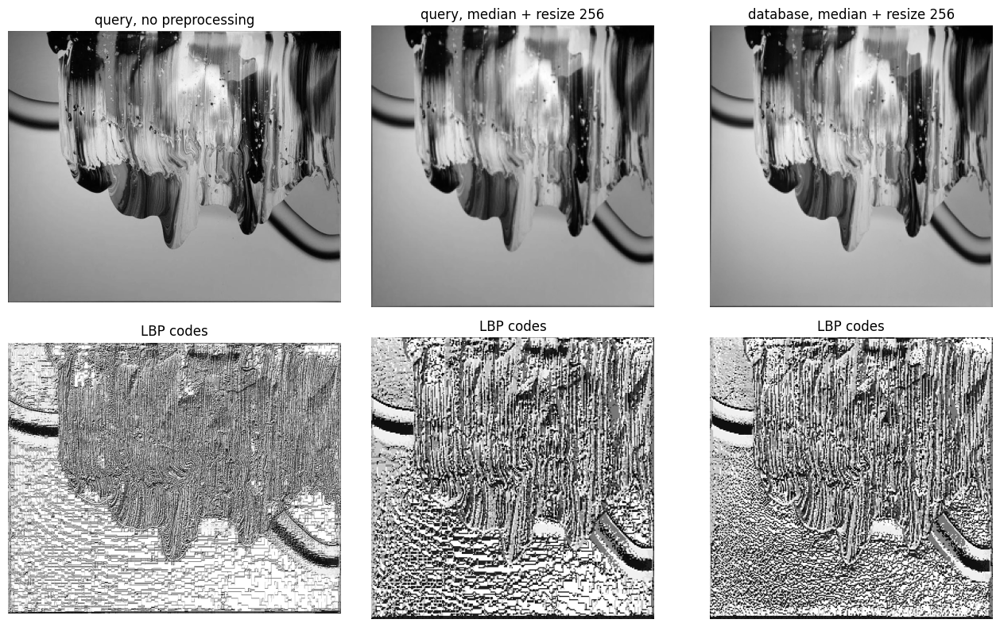

In [49]:
i = 0
gt_id = ground_truth[i][0]
db_img = db_imgs[list(db_ids).index(gt_id)]            # the correct painting

def lbp_img(im, den, size):
    im = preprocess(im, den)
    if size: im = cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)
    return local_binary_pattern(to_gray(im), 8, 1.0, method="default"), to_gray(im)

panels = [("query, no preprocessing", lbp_img(q_imgs[i], False, None)),
          ("query, median + resize 256", lbp_img(q_imgs[i], True, 256)),
          ("database, median + resize 256", lbp_img(db_img, True, 256))]
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for j, (title, (codes, g)) in enumerate(panels):
    ax[0, j].imshow(g, cmap="gray"); ax[0, j].set_title(title)
    ax[1, j].imshow(codes, cmap="gray"); ax[1, j].set_title("LBP codes")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

#### Effect of preprocessing on LBP (8 neighbours, radius 1, L1)
| pipeline | grid 4 mAP@1 / mAP@5 | grid 8 mAP@1 / mAP@5 |
|---|---|---|
| original size, filter queries only (first attempt) | 0.133 / 0.142 | 0.200 / 0.230 |
| original size, no filter | 0.433 / 0.461 | 0.600 / 0.623 |
| original size, filter queries and database | 0.600 / 0.633 | 0.767 / 0.775 |
| resize 256×256, filter queries only | 0.600 / 0.639 | 0.867 / 0.892 |
| resize 256×256, no filter | 0.733 / 0.789 | 0.867 / 0.867 |
| **resize 256×256, filter queries and database** | 0.733 / 0.800 | **0.933 / 0.944** |

- Resizing everything to the same size helps further, because LBP depends on the pixel scale.


In [50]:
dct_fn = lambda g: dct_descriptor(g, 8, 16, 10)
for size in (None, 256):
    for dq, dd, label in [(False, False, "no filter"), (True, False, "filter queries only"), (True, True, "filter queries and database")]:
        out = evaluate2(dct_fn, {"l1": l1}, db_imgs, q_imgs, db_ids, ground_truth, denoise_q=dq, denoise_db=dd, size=size)
        m1, m5, _ = out["l1"]
        print(f"DCT  size {str(size):<5} {label:<28} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

DCT  size None  no filter                    mAP@1 0.967  mAP@5 0.983
DCT  size None  filter queries only          mAP@1 0.967  mAP@5 0.983
DCT  size None  filter queries and database  mAP@1 0.967  mAP@5 0.983
DCT  size 256   no filter                    mAP@1 0.967  mAP@5 0.983
DCT  size 256   filter queries only          mAP@1 0.967  mAP@5 0.983
DCT  size 256   filter queries and database  mAP@1 0.967  mAP@5 0.983


DCT is **not affected** by the preprocessing: it gives mAP@1 0.967 and mAP@5 0.983 in all six pipelines. Each block is resized to 16×16 with area averaging (which removes isolated noisy pixels and scale differences) and only low-frequency coefficients are kept. LBP reads individual pixels, so it needs both sides to be treated in the same way. For this reason, from now on both descriptors use the same pipeline: **resize to 256×256 and median filter on queries and database**.

#### LBP with the final pipeline
With the common preprocessing, we compare the LBP variants (256 codes, uniform, multiscale uniform), block grids from 6×6 to 16×16 and three distances.

In [51]:
variants = {
    "8,1 default (256 bins)": dict(scales=((8, 1.0),), uniform=False),
    "8,1 uniform (10 bins)":  dict(scales=((8, 1.0),), uniform=True),
    "multiscale uniform":     dict(scales=((8, 1.0), (12, 2.5), (16, 4.0)), uniform=True),
}
lbp_final_rows = []
for vname, kw in variants.items():
    for grid in (6, 8, 12, 16):
        out = evaluate2(lambda g: lbp_descriptor(g, grid, **kw), dists_hist, db_imgs, q_imgs, db_ids, ground_truth,
                        denoise_q=True, denoise_db=True, size=256)
        for dname, (m1, m5, _) in out.items():
            lbp_final_rows.append((vname, grid, dname, m1, m5))
            print(f"{vname:<24} grid {grid:>2}  {dname:<9} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

8,1 default (256 bins)   grid  6  hellinger mAP@1 0.833  mAP@5 0.867
8,1 default (256 bins)   grid  6  chi2      mAP@1 0.833  mAP@5 0.875
8,1 default (256 bins)   grid  6  l1        mAP@1 0.833  mAP@5 0.883
8,1 default (256 bins)   grid  8  hellinger mAP@1 0.900  mAP@5 0.917
8,1 default (256 bins)   grid  8  chi2      mAP@1 0.900  mAP@5 0.917
8,1 default (256 bins)   grid  8  l1        mAP@1 0.933  mAP@5 0.944
8,1 default (256 bins)   grid 12  hellinger mAP@1 0.933  mAP@5 0.961
8,1 default (256 bins)   grid 12  chi2      mAP@1 0.933  mAP@5 0.961
8,1 default (256 bins)   grid 12  l1        mAP@1 0.967  mAP@5 0.973
8,1 default (256 bins)   grid 16  hellinger mAP@1 1.000  mAP@5 1.000
8,1 default (256 bins)   grid 16  chi2      mAP@1 1.000  mAP@5 1.000
8,1 default (256 bins)   grid 16  l1        mAP@1 1.000  mAP@5 1.000
8,1 uniform (10 bins)    grid  6  hellinger mAP@1 0.467  mAP@5 0.494
8,1 uniform (10 bins)    grid  6  chi2      mAP@1 0.467  mAP@5 0.500
8,1 uniform (10 bins)    grid  6  

In [39]:
for grid in (16, 20, 24):
    out = evaluate2(lambda g: lbp_descriptor(g, grid), dists_hist, db_imgs, q_imgs, db_ids, ground_truth,
                    denoise_q=True, denoise_db=True, size=256)
    for dname, (m1, m5, _) in out.items():
        print(f"grid {grid}  {dname:<9} mAP@1 {m1:.3f}  mAP@5 {m5:.3f}")

grid 16  hellinger mAP@1 1.000  mAP@5 1.000
grid 16  chi2      mAP@1 1.000  mAP@5 1.000
grid 16  l1        mAP@1 1.000  mAP@5 1.000
grid 20  hellinger mAP@1 1.000  mAP@5 1.000
grid 20  chi2      mAP@1 1.000  mAP@5 1.000
grid 20  l1        mAP@1 1.000  mAP@5 1.000
grid 24  hellinger mAP@1 1.000  mAP@5 1.000
grid 24  chi2      mAP@1 1.000  mAP@5 1.000
grid 24  l1        mAP@1 1.000  mAP@5 1.000


#### Final LBP
Chosen setting: LBP with 8 neighbours and radius 1 (256 codes), 16×16 blocks of the 256×256 image, L1 distance. mAP@1 1.000 / mAP@5 1.000 on QSD1-W3, texture only.
Results increase with the number of blocks and are identical for Hellinger, χ² and L1 at 16×16, so the choice does not depend on the distance. The uniform (10 bins) and multiscale variants were worse (0.733 and 0.867 mAP@1 at best). The setting was chosen on the 30 development queries (one query = 0.033), so the real score on unseen queries may be slightly lower.

#### DCT vs LBP (texture only, QSD1-W3, 30 queries)


In [52]:
import pandas as pd

rows = []
for name, fn, desc_len in [("DCT", lambda g: dct_descriptor(g, 8, 16, 10), 640),
                           ("LBP", lambda g: lbp_descriptor(g, 16), 65536)]:
    out = evaluate(fn, {"l1": l1}, db_imgs, q_imgs, db_ids, ground_truth,
                   denoise_queries=True, denoise_db=True, size=256)
    m1, m5, _ = out["l1"]
    out_bad = evaluate(fn, {"l1": l1}, db_imgs, q_imgs, db_ids, ground_truth)       # queries filtered only, original size
    rows.append((name, desc_len, out_bad["l1"][0], m1, m5))

table = pd.DataFrame(rows, columns=["descriptor", "values per image", "mAP@1 (queries filtered only)",
                                    "mAP@1 (same pipeline both sides)", "mAP@5 (same pipeline both sides)"])
display(table.round(3))


,descriptor,values per image,mAP@1 (queries filtered only),mAP@1 (same pipeline both sides),mAP@5 (same pipeline both sides)
0,DCT,640,0.967,0.967,0.983
1,LBP,65536,0.300,1.000,1.000
